# World Values Survey

## Датасет — 7-я волна World Values Survey: 97 220 респондентов из 66 стран

## 1. Проверка гипотез для различных доверительных уровней

В качестве гипотезы рассмотрим влияние различных уровней образования на финансовую удовлетворенность. Нулевая гипотеза - равенство. В односторонних критериях H1 — "у первой группы среднее меньше, чем у второй": у людей без высшего образования (у бакалавров) финансовая удовлетворённость ниже, чем у людей с высшим образованием (у магистров). Для начала рассмотрим гипотезу о различии в финансовой удовлетворенности между людьми не имеющими высшего образования вообще и теми кто имеет высшее образование любого уровня.

Далее я решил рассмотреть различие уже между уровнями высшего образования, то есть различия в финансовой удовлетворенности между людьми имеющими степень бакалавра и людьми имеющими степень магистра.

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import scipy.stats as stats
import statsmodels.stats.power as power

df = pd.read_csv("wvs.csv")

df = df.drop(columns=["Sector_of_employment"])
df = df.dropna()

mask = df["Education_level"] <= 4
mask2 = (df["Education_level"] >= 6) & (df["Education_level"] < 9)

mask_bac = df["Education_level"] == 6
mask_master = df["Education_level"] == 7

# a) Уэлч / Стьюдент / Мощности

# t-тест Уэлча (для разных дисперсий)

a = stats.ttest_ind(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask2], equal_var=False, alternative="two-sided") # двусторонний

b = stats.ttest_ind(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask2], equal_var=False, alternative="less") # односторонний

print("Двусторонний Критерий Уэлча для разных дисперсий.")

df_t = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_t)

print("Односторонний Критерий Уэлча для разных дисперсий.")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [b.pvalue, b.pvalue, b.pvalue],
    "принимаем H1": [b.pvalue<0.1, b.pvalue<0.05, b.pvalue<0.01]
})

display(df_g)

x = df["Financial_satisfaction"][mask]
y = df["Financial_satisfaction"][mask2]

n1 = x.count()
n2 = y.count()

sp = np.sqrt(((n1 - 1) * x.var() + (n2 - 1) * y.var()) / (n1 + n2 - 2))
d = abs(x.mean() - y.mean()) / sp

print(f"Эффект Коэна: d = {d}")

# Критерий Стьюдента (при одинаковых дисперсиях)

a = stats.ttest_ind(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master], equal_var=True, alternative="two-sided") # двусторонний

b = stats.ttest_ind(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master], equal_var=True, alternative="less") # односторонний

print("Двусторонний Критерий Стьюдента для одинаковых дисперсий.")

df_t = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_t)

print("Односторонний критерий Стьюдента для одинаковых дисперсий.")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [b.pvalue, b.pvalue, b.pvalue],
    "принимаем Н1": [b.pvalue<0.1, b.pvalue<0.05, b.pvalue<0.01]
})

display(df_g)

# Мощность критерия Стьюдента 

tt = power.TTestIndPower()

x = df["Financial_satisfaction"][mask_bac]
y = df["Financial_satisfaction"][mask_master]

n1 = x.count()
n2 = y.count()

sp = np.sqrt(((n1 - 1) * x.var() + (n2 - 1) * y.var()) / (n1 + n2 - 2))
d = abs(x.mean() - y.mean()) / sp

ratio = n2 / n1

print(f"Эффект Коэна: d = {d}")

N_90 = tt.power(effect_size=d, nobs1=n1, alpha=0.1, ratio=ratio, alternative="two-sided")
N_95 = tt.power(effect_size=d, nobs1=n1, alpha=0.05, ratio=ratio, alternative="two-sided")
N_99 = tt.power(effect_size=d, nobs1=n1, alpha=0.01, ratio=ratio, alternative="two-sided")

print(f"Мощность двустороннего критерия Стьюдента: 0.90 - {N_90}, 0.95 - {N_95}, 0.99 - {N_99}\n")

# Обратная задача: какой объём выборки нужен для мощности 0.8 и 0.9 (уровень 0.95)

n_08 = tt.solve_power(effect_size=d, nobs1=None, alpha=0.05, power=0.8, ratio=ratio, alternative="two-sided")
n_09 = tt.solve_power(effect_size=d, nobs1=None, alpha=0.05, power=0.9, ratio=ratio, alternative="two-sided")

print(f"Для мощности 0.8 нужно бакалавров: {n_08}, магистров: {n_08 * ratio}")
print(f"Для мощности 0.9 нужно бакалавров: {n_09}, магистров: {n_09 * ratio}")
print(f"Реальная выборка: бакалавров {n1}, магистров {n2}\n")

# Критерий Манна-Уитни

a = stats.mannwhitneyu(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master], alternative="two-sided")
b = stats.mannwhitneyu(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master], alternative="less")

print(f"Двусторонний Критерий Манна-Уитни.")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_g)

print(f"Односторонний Критерий Манна-Уитни.")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [b.pvalue, b.pvalue, b.pvalue],
    "принимаем Н1": [a.pvalue<0.1, a.pvalue<0.05, a.pvalue<0.01]
})

display(df_g)

# Bartlett

a = stats.bartlett(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master])

print(f"Критерий Бартлетта (равенство дисперсий).")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_g)

# Levene

a = stats.levene(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master], center="mean")

print(f"Критерий Левенe (равенство дисперсий).")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_g)

# Fligner

a = stats.fligner(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master])

print(f"Критерий Флигнера (равенство дисперсий).")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_g)

# Fisher

def fisher_test(x, y, alternative="two-sided"):
    
    F = np.var(x, ddof=1) / np.var(y, ddof=1)
    d1 = len(x) - 1
    d2 = len(y) - 1

    if alternative == "two-sided":
        p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
    elif alternative == "greater":
        p = stats.f.sf(F, d1, d2)
    else:
        p = stats.f.cdf(F, d1, d2)

    return F, min(p, 1.0)


F, p = fisher_test(df["Financial_satisfaction"][mask_bac], df["Financial_satisfaction"][mask_master])

print(f"Критерий Фишера (равенство дисперсий).")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [p, p, p],
    "не отвергаем H0": [p > 0.1, p > 0.05, p > 0.01]
})

display(df_g)

Двусторонний Критерий Уэлча для разных дисперсий.


,alpha,p-value,не отвергаем H0
0,0.10,1.445409e-147,False
1,0.05,1.445409e-147,False
2,0.01,1.445409e-147,False


Односторонний Критерий Уэлча для разных дисперсий.


,alpha,p-value,принимаем H1
0,0.10,7.227047e-148,True
1,0.05,7.227047e-148,True
2,0.01,7.227047e-148,True


Эффект Коэна: d = 0.27792697465905786
Двусторонний Критерий Стьюдента для одинаковых дисперсий.


,alpha,p-value,не отвергаем H0
0,0.10,0.000124,False
1,0.05,0.000124,False
2,0.01,0.000124,False


... (10 outputs left out)

Критерий Флигнера (равенство дисперсий).


,alpha,p-value,не отвергаем H0
0,0.10,0.349025,True
1,0.05,0.349025,True
2,0.01,0.349025,True


Критерий Фишера (равенство дисперсий).


,alpha,p-value,не отвергаем H0
0,0.10,0.933583,True
1,0.05,0.933583,True
2,0.01,0.933583,True


Вывод: нулевая гипотеза о равенстве ожидаемо отвергнута критерием Уэлча: наличие высшего образования напрямую влияет на финансовую удовлетворенность, эффект Коэна d=0.28 - небольшой. 

Дисперсии в финансовой удовлетворенности у имеющих степени бакалавра и имеющих степени магистра оказались почти равны. Критерии Левене, Бартлетта, Флигнера и Фишера не отвергли нулевую гипотезу о равенстве дисперсий, поэтому был применен критерий Стьюдента, который показал различия в финансовой удовлетворенности между людьми имеющими разные степени образования, причем для всех доверительных уровней, хотя эффект Коэна d=0.09 - почти нулевой, а односторонний критерий подтвердил альтернативную гипотезу о том что у имеющих степень магистра выше финансовая удовлетворенность.

## 2. Корреляционные взаимосвязи. Коэффициенты корреляции Пирсона, Спирмена и Кендалла

Зависимость между количеством людей в домохозяйстве и финансовой удовлетворенностью / субъективным ощущением дохода. То, что люди с низкой удовлетворенностью доходами и доходом в целом имеют больше людей в домохозяйстве либо ввиду того, что у них мало финансов на личное жилье либо ввиду того, что им нужно больше людей для работы (например, сельские местности). Люди со средним достатком обычно ограничиваются количеством людей, тогда как богатые люди имеют возможность приобрести себе большую жилплощадь и соответственно позволить себе, например, большое количество детей или людей проживающих с ними. Построим новый признак для расчета финансовой состоятельности: сложить + нормировать такие признаки как "финансовая удовлетворенность", "субъективное ощущение доходов" и "социальный класс". Это нам нужно для построения диаграммы рассеяния, так-как ее будет трудно и бессмысленно строить для "слишком дискретных" признаков. Далее будет рассмотрена также корреляция между принадлежностью к социальному классу, а также достатком и финансовой удовлетворенностью, но не будет строиться диаграмма рассеяния ввиду своей бесполезности для дискретных данных.

Исследуем различные коэффициенты корреляции между индексом достатка и размером домохозяйства и числом детей.


,Names,Pearson,Spearman,Kendall
0,Household_size,-0.031897,-0.026240,-0.019136
1,Number_of_children,-0.109420,-0.091043,-0.067337


Исследуем корреляцию между социальным классом и субъективным ощущением своего достатка и удовлетворенностью своим финансовым состоянием.


,Names,Pearson,Spearman,Kendall
0,Income_scale,-0.494727,-0.494734,-0.416476
1,Financial_satisfaction,-0.249827,-0.240942,-0.194993


Далее показаны диаграммы рассеяния между посчитанным индексом финансового благополучия и размером домохозяйств и числа детей.


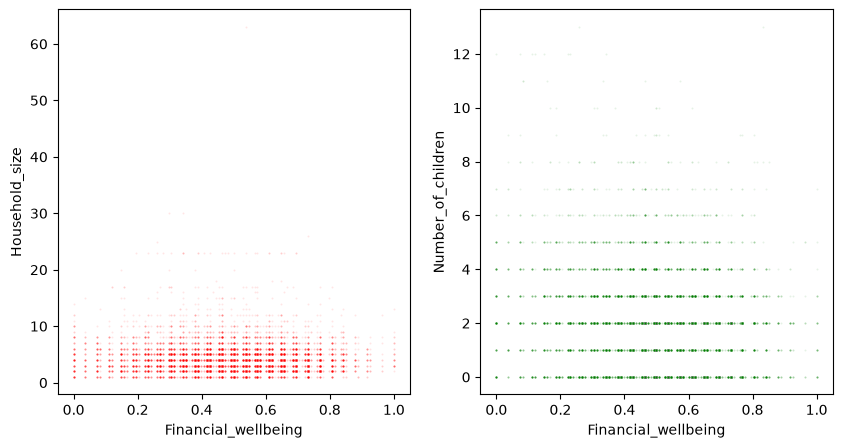

In [9]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 

df = pd.read_csv("wvs.csv")

df = df.drop(columns=["Sector_of_employment", "Education_level"])
df = df.dropna()
df = df.sample(10000, random_state = 42) # чтобы точки меньше друг на друга накладывались
df = df.reset_index(drop=True)

series_new = ((df["Financial_satisfaction"]-1)/9+(df["Income_scale"]-1)/9+(5-df["Social_class"])/4) / 3
df["Financial_wellbeing"] = series_new

# stats

print("Исследуем различные коэффициенты корреляции между индексом достатка и размером домохозяйства и числом детей.")

corr = pd.DataFrame({
    "Names": ["Household_size", "Number_of_children"],
    "Pearson": [stats.pearsonr(df["Financial_wellbeing"], df["Household_size"]).statistic, stats.pearsonr(df["Financial_wellbeing"], df["Number_of_children"]).statistic], 
    "Spearman": [stats.spearmanr(df["Financial_wellbeing"], df["Household_size"]).statistic, stats.spearmanr(df["Financial_wellbeing"], df["Number_of_children"]).statistic],
    "Kendall": [stats.kendalltau(df["Financial_wellbeing"], df["Household_size"]).statistic, stats.kendalltau(df["Financial_wellbeing"], df["Number_of_children"]).statistic]
})

display(corr)

print("Исследуем корреляцию между социальным классом и субъективным ощущением своего достатка и удовлетворенностью своим финансовым состоянием.")

corr1 = pd.DataFrame({
    "Names": ["Income_scale", "Financial_satisfaction"],
    "Pearson": [stats.pearsonr(df["Social_class"], df["Income_scale"]).statistic, stats.pearsonr(df["Social_class"], df["Financial_satisfaction"]).statistic], 
    "Spearman": [stats.spearmanr(df["Social_class"], df["Income_scale"]).statistic, stats.spearmanr(df["Social_class"], df["Financial_satisfaction"]).statistic],
    "Kendall": [stats.kendalltau(df["Social_class"], df["Income_scale"]).statistic, stats.kendalltau(df["Social_class"], df["Financial_satisfaction"]).statistic]
})

display(corr1)

# графики

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

print("Далее показаны диаграммы рассеяния между посчитанным индексом финансового благополучия и размером домохозяйств и числа детей.")

sns.scatterplot(df, x="Financial_wellbeing", y="Household_size", s=2, alpha=0.1, ax=axes[0], color="red")
sns.scatterplot(df, x="Financial_wellbeing", y="Number_of_children", s=2, alpha=0.1, ax=axes[1], color="green");

Вывод: как и ожидалось, линейной корреляции почти нет, так как она по вышеназванному предположению в принципе не монотонна.
При этом есть слабая отрицательная корреляция между количеством детей и индексом финансового благополучия. Диаграммы рассеяния показывают очевидное отсутствие линейной зависимости между индексом финансового благополучия и числом детей или размером домохозяйства. В целом если судить по коэффициентам Спирмена и Кендалла, то монотонной связи действительно вообще нет.

Есть очевидная заметная корреляция между социальным классом и субективным ощущением своего дохода по сравнению с другими,
но удовлетворенность своим финансовым благополучием имеет слабую корреляцию с социальным классом.

## 3. Методы хи-квадрат, тест Фишера, тест МакНемара, Кохрана-Мантеля-Хензеля

Методы проверки независимости категориальных признаков. Исследуем, связан ли пол человека с тем, живёт ли он с родителями. Для хи-квадрат, теста Фишера и теста Кохрана–Мантеля–Хензеля нулевая гипотеза — независимость признаков. Тест МакНемара применяется только к парным данным (два ответа одного человека), поэтому для него взята другая пара: удовлетворённость жизнью и финансами.

In [10]:
import numpy as np 
import pandas as pd 
import scipy.stats as stats
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.contingency_tables import StratifiedTable

df = pd.read_csv('wvs.csv')

df = df.drop(columns=["Sector_of_employment", "Education_level"])
df = df.dropna()

mask_p = df["Live_with_parents"] <= 2

# Gender: 1 - мужчины, 2 - женщины
# Live_with_parents: 1 - не живёт с родителями, 2 - живёт

freq = pd.crosstab(df["Gender"][mask_p], df["Live_with_parents"][mask_p])

print("Таблица частот: пол и живет ли человек с родителями.")
display(freq)

# метод хи-квадрат (H0 - пол и проживание с родителями независимы)

h = stats.chi2_contingency(freq)

# тест Фишера (как хи-квадрат только на малых выборках)

f = stats.fisher_exact(freq)

# тест Фишера на малой выборке (40 человек)

small = df[mask_p].sample(40, random_state=42)

freq_small = pd.crosstab(small["Gender"], small["Live_with_parents"])

print("Малая выборка:")
display(freq_small)

print("Ожидаемые частоты для малой выборки (меньше 5 - хи-квадрат неприменим):")
display(stats.chi2_contingency(freq_small).expected_freq)

f_small = stats.fisher_exact(freq_small)

# тест Кохрана-Мантеля-Хензеля (H0: признаки независимы внутри каждой возрастной группы)

mask_age1 = df["Age"]<=18
mask_age2 = (df["Age"]<=40) & (df["Age"]>18)
mask_age3 = (df["Age"]<=103) & (df["Age"]>40)

freq1 = pd.crosstab(df["Gender"][mask_p & mask_age1], df["Live_with_parents"][mask_p & mask_age1])
freq2 = pd.crosstab(df["Gender"][mask_p & mask_age2], df["Live_with_parents"][mask_p & mask_age2])
freq3 = pd.crosstab(df["Gender"][mask_p & mask_age3], df["Live_with_parents"][mask_p & mask_age3])

print("Таблицы по возрастным группам: до 18, 18-40, старше 40.")
display(freq1)
display(freq2)
display(freq3)

freq1_np = freq1.to_numpy()
freq2_np = freq2.to_numpy()
freq3_np = freq3.to_numpy()

freqs = np.stack([freq1_np, freq2_np, freq3_np], axis=2)

st = StratifiedTable(freqs)
hs = st.test_null_odds()

# тест МакНемара (парные данные: два ответа одного человека)
# H0: доля удовлетворённых жизнью (>= 7) равна доле удовлетворённых финансами (>= 7)

life = np.where(df["Life_satisfaction"] >= 7, "да", "нет")
fin = np.where(df["Financial_satisfaction"] >= 7, "да", "нет")

freq_mc = pd.crosstab(life, fin, rownames=["Удовлетворён жизнью"], colnames=["Удовлетворён финансами"])

print("Таблица для теста МакНемара.")
display(freq_mc)

mc = mcnemar(freq_mc, exact=False)

dff = pd.DataFrame({
    "методы": ["Хи-квадрат", "Фишер", "Фишер (40 человек)", "Кохран-Мантель-Хензель", "МакНемар"],
    "p-value": [h.pvalue, f.pvalue, f_small.pvalue, hs.pvalue, mc.pvalue],
    "не отвергаем H0": [h.pvalue>0.05, f.pvalue>0.05, f_small.pvalue>0.05, hs.pvalue>0.05, mc.pvalue>0.05]
})

print("Результаты проверки гипотез.")
display(dff)

Таблица частот: пол и живет ли человек с родителями.


Live_with_parents,1.0,2.0
Gender,,
1.0,22783,8737
2.0,24388,6885


Малая выборка:


Live_with_parents,1.0,2.0
Gender,,
1.0,13,3
2.0,20,4


Ожидаемые частоты для малой выборки (меньше 5 - хи-квадрат неприменим):


array([[13.2,  2.8],
       [19.8,  4.2]])

... (4 outputs left out)

Таблица для теста МакНемара.


Удовлетворён финансами,да,нет
Удовлетворён жизнью,,
да,27958,14959
нет,4015,19634


Результаты проверки гипотез.


,методы,p-value,не отвергаем H0
0,Хи-квадрат,2.655839e-61,False
1,Фишер,1.964009e-61,False
2,Фишер (40 человек),1.000000e+00,True
3,Кохран-Мантель-Хензель,0.000000e+00,False
4,МакНемар,0.000000e+00,False


Вывод: хи-квадрат и тест Фишера отвергают гипотезу о независимости, то есть пол и проживание с родителями связаны: по таблице видно, что мужчины чаще живут с родителями, чем женщины. Разница при этом небольшая, а значимой её делает большой объём выборки: на малой выборке из 40 человек (где хи-квадрат неприменим, так как ожидаемые частоты меньше 5) тест Фишера уже не отвергает независимость. Тест Кохрана–Мантеля–Хензеля тоже отвергает независимость, значит, связь сохраняется и с учётом возраста. Тест МакНемара показал, что доля людей, довольных жизнью, значимо больше доли довольных своими финансами.

## 4. Проверка мультиколлинеарности данных с помощью корреляционной матрицы и фактора инфляции дисперсии.

4.1 Матрица корреляций. Удалим из данных категориальные признаки, нечисловые и неупорядоченные признаки для большей наглядности. Стоит помнить, что некоторые признаки имеют обратные шкалы, например где-то 1 - "самый положительный" результат, где-то - наоборот.

Корреляционная матрица признаков. Для наглядности были удалены категориальные признаки.


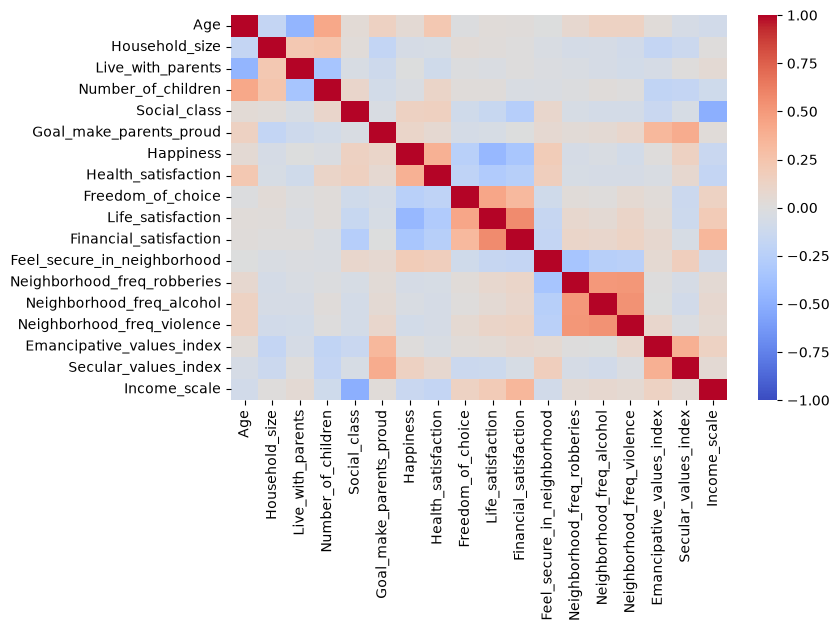

In [11]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats

df = pd.read_csv("wvs.csv")
mask_p = df["Live_with_parents"] <= 2
df = df[mask_p]

# считаем корреляционную матрицу
 
df = df.drop(columns=["Country", "Equality_subindex", "Voice_subindex", "Defiance_subindex", "Choice_subindex", "Disbelief_subindex", "Autonomy_subindex", "Education_level", "Trust_known_personally", "Occupational_group", "Gender", "Success_luck_vs_work", "Standard_of_living_vs_parents", "Competition_is_good", "Sector_of_employment", "Unable_afford_child_education", "Most_important_national_aim", "Employment_status", "Marital_status"], errors="ignore")

corr = df.corr(method="pearson") # матрица корреляций

fig, axes = plt.subplots(figsize=(8, 5))

print("Корреляционная матрица признаков. Для наглядности были удалены категориальные признаки.")

sns.heatmap(corr, annot=False, cmap="coolwarm", fmt=".1f", vmin=-1, vmax=1);

Вывод: как видно из матрицы корреляций, большинство признаков друг с другом не коррелируют вообще или корреляция слабая. Умеренная корреляция видна только там, где это очевидно, например люди с более традиционными взглядами склонны чаще считать важной цель "стать гордостью родителей", но даже тут корреляция заметная, но не сильная. Также умеренная корреляция наблюдается например в признаках "ограбления в районах" и "распитие алкоголя в районах" что тоже достаточно очевидно. Сильной корреляции нет нигде, что нормально для социальных опросов.

4.2 Фактор инфляции дисперсии (VIF). Попробуем посчитать VIF для удовлетворенности жизнью с учетом социального класса, удовлетворенностью финансами и здоровьем, а также доходом.

In [12]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 
import statsmodels.api as mdl
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("wvs.csv")

df = df.drop(columns=["Country", "Equality_subindex", "Voice_subindex", "Defiance_subindex", "Choice_subindex", "Disbelief_subindex", "Autonomy_subindex", "Education_level", "Trust_known_personally", "Occupational_group", "Success_luck_vs_work", "Standard_of_living_vs_parents", "Competition_is_good", "Sector_of_employment", "Unable_afford_child_education", "Most_important_national_aim"], errors="ignore")

df = df.dropna()
df = df.reset_index(drop=True)

def vif_table(df, columns):
    data = df[columns].dropna()
    X = mdl.add_constant(data)
    return pd.DataFrame({
        "признак": columns,
        "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
    })

# Посмотрим теперь зависимость удовлетворенности жизнью с учетом разных признаков

l1 = ["Life_satisfaction", "Social_class", "Health_satisfaction", "Financial_satisfaction", "Income_scale"]

l2 = ["Feel_secure_in_neighborhood", "Neighborhood_freq_violence", "Neighborhood_freq_alcohol", "Neighborhood_freq_robberies"]

display(vif_table(df, l1))
display(vif_table(df, l2))

,признак,VIF
0,Life_satisfaction,1.512721
1,Social_class,1.353699
2,Health_satisfaction,1.114608
3,Financial_satisfaction,1.614531
4,Income_scale,1.434055


,признак,VIF
0,Feel_secure_in_neighborhood,1.154138
1,Neighborhood_freq_violence,1.560427
2,Neighborhood_freq_alcohol,1.543982
3,Neighborhood_freq_robberies,1.589160


Вывод: мультиколлинеарности в данных нет (VIF<5). Для социальных данных, особенно опросных, высокие корреляции встречаются редко, а умеренные корреляции дают значение VIF не больше чем 1.5-2. В целом как можно видеть даже при наличии многих умеренных парных корреляций мультиколлинеарности может не быть, что мы видим на примере признаков про безопасность которые имеют умеренные парные корреляции.

## 5. Исследование зависимости в данных с помощью дисперсионного анализа. Модификация Уэлча. Критерий Краскела-Уоллиса

Известно, что в середине двадцатого века после Второй мировой войны многие страны Восточной Азии совершили "экономическое чудо" и стали стремительно развиваться. Посмотрим, насколько различаются показатели уровня жизни, финансовой удовлетворенности и дохода у данных стран, предположив, что сейчас они на одном уровне.

In [13]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 

df = pd.read_csv("wvs.csv")
df = df.drop(columns=["Sector_of_employment", "Education_level"])
df = df.dropna()

mask = df["Country"] == "SGP"
mask2 = df["Country"] == "JPN"
mask3 = df["Country"] == "KOR"
mask4 = df["Country"] == "HKG"
mask5 = df["Country"] == "TWN"

# Levene

a = stats.levene(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask2], df["Financial_satisfaction"][mask3], df["Financial_satisfaction"][mask4], df["Financial_satisfaction"][mask5], center="mean")

print(f"Критерий Левене (равенство дисперсий).")

df_g = pd.DataFrame({
    "alpha": [0.1, 0.05, 0.01],
    "p-value": [a.pvalue, a.pvalue, a.pvalue],
    "не отвергаем H0": [a.pvalue>0.1, a.pvalue>0.05, a.pvalue>0.01]
})

display(df_g)

# Дисперсионный анализ, модификация Уэлча (не требует равенства дисперсий)

ls_w = stats.f_oneway(df["Life_satisfaction"][mask], df["Life_satisfaction"][mask2], df["Life_satisfaction"][mask3], df["Life_satisfaction"][mask4], df["Life_satisfaction"][mask5], equal_var=False)

fs_w = stats.f_oneway(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask2], df["Financial_satisfaction"][mask3], df["Financial_satisfaction"][mask4], df["Financial_satisfaction"][mask5], equal_var=False)

is_w = stats.f_oneway(df["Income_scale"][mask], df["Income_scale"][mask2], df["Income_scale"][mask3], df["Income_scale"][mask4], df["Income_scale"][mask5], equal_var=False)

hs_w = stats.f_oneway(df["Health_satisfaction"][mask], df["Health_satisfaction"][mask2], df["Health_satisfaction"][mask3], df["Health_satisfaction"][mask4], df["Health_satisfaction"][mask5], equal_var=False)

sc_w = stats.f_oneway(df["Social_class"][mask], df["Social_class"][mask2], df["Social_class"][mask3], df["Social_class"][mask4], df["Social_class"][mask5], equal_var=False)

feel_sec_w = stats.f_oneway(df["Feel_secure_in_neighborhood"][mask], df["Feel_secure_in_neighborhood"][mask2], df["Feel_secure_in_neighborhood"][mask3], df["Feel_secure_in_neighborhood"][mask4], df["Feel_secure_in_neighborhood"][mask5], equal_var=False)

df_w = pd.DataFrame({
    "names": ["Удовлетворенность жизнью", "Финансовая удовлетворенность", "Субъективное ощущение дохода", "Удовлетворенность здоровьем", "Социальный класс", "Ощущение безопасности"],
    "pvalue": [ls_w.pvalue, fs_w.pvalue, is_w.pvalue, hs_w.pvalue, sc_w.pvalue, feel_sec_w.pvalue],
    "не отвергаем H0": [ls_w.pvalue>0.05, fs_w.pvalue>0.05, is_w.pvalue>0.05, hs_w.pvalue>0.05, sc_w.pvalue>0.05, feel_sec_w.pvalue>0.05]
})

print("Дисперсионный анализ Уэлча. Не требует равенства дисперсий. Страны: Япония, Южная Корея, Сингапур, Гонконг, Тайвань.")

display(df_w)

print("Уэлч для Сингапура, Гонконга и Тайваня.")

ls_w = stats.f_oneway(df["Life_satisfaction"][mask], df["Life_satisfaction"][mask4], df["Life_satisfaction"][mask5], equal_var=False)

fs_w = stats.f_oneway(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask4], df["Financial_satisfaction"][mask5], equal_var=False)

is_w = stats.f_oneway(df["Income_scale"][mask], df["Income_scale"][mask4], df["Income_scale"][mask5], equal_var=False)

hs_w = stats.f_oneway(df["Health_satisfaction"][mask], df["Health_satisfaction"][mask4], df["Health_satisfaction"][mask5], equal_var=False)

sc_w = stats.f_oneway(df["Social_class"][mask], df["Social_class"][mask4], df["Social_class"][mask5], equal_var=False)

feel_sec_w = stats.f_oneway(df["Feel_secure_in_neighborhood"][mask], df["Feel_secure_in_neighborhood"][mask4], df["Feel_secure_in_neighborhood"][mask5], equal_var=False)

df_w = pd.DataFrame({
    "names": ["Удовлетворенность жизнью", "Финансовая удовлетворенность", "Субъективное ощущение дохода", "Удовлетворенность здоровьем", "Социальный класс", "Ощущение безопасности"],
    "pvalue": [ls_w.pvalue, fs_w.pvalue, is_w.pvalue, hs_w.pvalue, sc_w.pvalue, feel_sec_w.pvalue],
    "не отвергаем H0": [ls_w.pvalue>0.05, fs_w.pvalue>0.05, is_w.pvalue>0.05, hs_w.pvalue>0.05, sc_w.pvalue>0.05, feel_sec_w.pvalue>0.05]
})

display(df_w)

# Критерий Краскела-Уоллиса (если данные откровенно ненормальны)

ls_kr = stats.kruskal(df["Life_satisfaction"][mask], df["Life_satisfaction"][mask2], df["Life_satisfaction"][mask3], df["Life_satisfaction"][mask4], df["Life_satisfaction"][mask5])

fs_kr = stats.kruskal(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask2], df["Financial_satisfaction"][mask3], df["Financial_satisfaction"][mask4], df["Financial_satisfaction"][mask5])

is_kr = stats.kruskal(df["Income_scale"][mask], df["Income_scale"][mask2], df["Income_scale"][mask3], df["Income_scale"][mask4], df["Income_scale"][mask5])

hs_kr = stats.kruskal(df["Health_satisfaction"][mask] ,df["Health_satisfaction"][mask2], df["Health_satisfaction"][mask3], df["Health_satisfaction"][mask4], df["Health_satisfaction"][mask5])

sc_kr = stats.kruskal(df["Social_class"][mask], df["Social_class"][mask2], df["Social_class"][mask3] ,df["Social_class"][mask4], df["Social_class"][mask5])

feel_sec_kr = stats.kruskal(df["Feel_secure_in_neighborhood"][mask], df["Feel_secure_in_neighborhood"][mask2], df["Feel_secure_in_neighborhood"][mask3], df["Feel_secure_in_neighborhood"][mask4], df["Feel_secure_in_neighborhood"][mask5])

df_kr = pd.DataFrame({
    "names": ["Удовлетворенность жизнью", "Финансовая удовлетворенность", "Субъективное ощущение дохода", "Удовлетворенность здоровьем", "Социальный класс", "Ощущение безопасности"],
    "pvalue": [ls_kr.pvalue, fs_kr.pvalue, is_kr.pvalue, hs_kr.pvalue, sc_kr.pvalue, feel_sec_kr.pvalue],
    "не отвергаем H0": [ls_kr.pvalue>0.05, fs_kr.pvalue>0.05, is_kr.pvalue>0.05, hs_kr.pvalue>0.05, sc_kr.pvalue>0.05, feel_sec_kr.pvalue>0.05]
})

print("Критерий Краскела-Уоллиса. Не требует нормальности. Страны: Япония, Южная Корея, Сингапур, Гонконг, Тайвань.")

display(df_kr)

print("Попробуем для стран с похожей историей экономического развития, то есть сравним Сингапур, Гонконг и Тайвань.")

ls_kr = stats.kruskal(df["Life_satisfaction"][mask], df["Life_satisfaction"][mask4], df["Life_satisfaction"][mask5])

fs_kr = stats.kruskal(df["Financial_satisfaction"][mask], df["Financial_satisfaction"][mask4], df["Financial_satisfaction"][mask5])

is_kr = stats.kruskal(df["Income_scale"][mask], df["Income_scale"][mask4], df["Income_scale"][mask5])

hs_kr = stats.kruskal(df["Health_satisfaction"][mask], df["Health_satisfaction"][mask4], df["Health_satisfaction"][mask5])

sc_kr = stats.kruskal(df["Social_class"][mask], df["Social_class"][mask4], df["Social_class"][mask5])

feel_sec_kr = stats.kruskal(df["Feel_secure_in_neighborhood"][mask], df["Feel_secure_in_neighborhood"][mask4], df["Feel_secure_in_neighborhood"][mask5])

df_kr = pd.DataFrame({
    "names": ["Удовлетворенность жизнью", "Финансовая удовлетворенность", "Субъективное ощущение дохода", "Удовлетворенность здоровьем", "Социальный класс", "Ощущение безопасности"],
    "pvalue": [ls_kr.pvalue, fs_kr.pvalue, is_kr.pvalue, hs_kr.pvalue, sc_kr.pvalue, feel_sec_kr.pvalue],
    "не отвергаем H0": [ls_kr.pvalue>0.05, fs_kr.pvalue>0.05, is_kr.pvalue>0.05, hs_kr.pvalue>0.05, sc_kr.pvalue>0.05, feel_sec_kr.pvalue>0.05]
})

display(df_kr)

Критерий Левене (равенство дисперсий).


,alpha,p-value,не отвергаем H0
0,0.10,9.173498e-29,False
1,0.05,9.173498e-29,False
2,0.01,9.173498e-29,False


Дисперсионный анализ Уэлча. Не требует равенства дисперсий. Страны: Япония, Южная Корея, Сингапур, Гонконг, Тайвань.


,names,pvalue,не отвергаем H0
0,Удовлетворенность жизнью,1.863880e-15,False
1,Финансовая удовлетворенность,8.745553e-05,False
2,Субъективное ощущение дохода,1.010177e-09,False
3,Удовлетворенность здоровьем,6.454562e-135,False
4,Социальный класс,1.876197e-18,False
5,Ощущение безопасности,4.672816e-217,False


Уэлч для Сингапура, Гонконга и Тайваня.


,names,pvalue,не отвергаем H0
0,Удовлетворенность жизнью,4.669938e-15,False
1,Финансовая удовлетворенность,1.855330e-02,False
2,Субъективное ощущение дохода,2.034462e-07,False
3,Удовлетворенность здоровьем,4.372179e-70,False
4,Социальный класс,6.400142e-04,False
5,Ощущение безопасности,8.168533e-104,False


Критерий Краскела-Уоллиса. Не требует нормальности. Страны: Япония, Южная Корея, Сингапур, Гонконг, Тайвань.


,names,pvalue,не отвергаем H0
0,Удовлетворенность жизнью,1.213402e-21,False
1,Финансовая удовлетворенность,3.887956e-06,False
2,Субъективное ощущение дохода,7.279653e-16,False
3,Удовлетворенность здоровьем,2.827859e-119,False
4,Социальный класс,7.396495e-18,False
5,Ощущение безопасности,1.353989e-231,False


Попробуем для стран с похожей историей экономического развития, то есть сравним Сингапур, Гонконг и Тайвань.


,names,pvalue,не отвергаем H0
0,Удовлетворенность жизнью,7.419677e-17,False
1,Финансовая удовлетворенность,8.825809e-03,False
2,Субъективное ощущение дохода,3.013554e-08,False
3,Удовлетворенность здоровьем,6.377831e-74,False
4,Социальный класс,9.286026e-05,False
5,Ощущение безопасности,2.869867e-110,False


Вывод: Ввиду различия дисперсий (выявлено критерием Левене) классический ANOVA применять здесь не имеет смысла, поэтому были применены критерий Уэлча и критерий Краскела-Уоллиса. У всех 5 стран достаточно разные показатели экономических признаков. Взяв 3 страны с похожей историей развития, пришли к выводу, что там аналогичным образом различаются показатели экономических признаков, но эти различия уже менее заметны (финансовое благополучие в принципе не отвергается на уровне значимости 0.01), что может говорить о том, что похожая история развития играет роль, но не такую большую, как могло показаться. Все страны начинали с иностранной поддержки (Великобритания, США), а также ввиду отсутствия ресурсов инвестировали в образование и занимались производством электроники, например полупроводников. Тем не менее, по остальным признакам различия значимы на всех уровнях.

## 6. Линейные и нелинейные регрессионные модели. Оценка качества данных аппроксимаций

Для построения линейной регрессии обратимся к матрице корреляций и выберем признаки со значимой корреляцией. Для построения множественной линейной регрессии выберем признаки с невысоким VIF. Для построения полиномиальной регрессии изучим другие закономерности.

In [14]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats
import scipy.optimize as opt
import statsmodels.api as mdl

df = pd.read_csv("wvs.csv")
df = df.drop(columns=["Sector_of_employment", "Education_level"])
df = df.dropna()

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def rsq(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

# линейная регрессия: Зависимость удовлетворенности жизни от удовлтеворенности доходами (независимая переменная)

lr = stats.linregress(df["Financial_satisfaction"], df["Life_satisfaction"]) # y = ax+b

print(f"функция линейной регрессии: y={lr.slope}*x+{lr.intercept}")
print("x - Финансовая удовлетворенность, у - удовлетворенность жизнью\n")

# множественная линейная регрессия: Зависимость удовлетворенности жизни от удовлетворенности доходами и свободой выбора

x = mdl.add_constant(df[["Financial_satisfaction", "Freedom_of_choice"]]).to_numpy()  # добавили столбец единиц

lrr = opt.lsq_linear(x, df["Life_satisfaction"]) # y = d + a*x1 + b*x2

print(f"функция линейной регрессии: y={lrr.x[0]}+{lrr.x[1]}*x1+{lrr.x[2]}*x2")
print("x1 - Финансовая удовлетворенность, х2 - ощущение свободы выбора, у - удовлетворенность жизнью\n")

# нелинейная регрессия: зависимость количества людей проживающих в домохозяйстве от субъективного ощущения дохода

def quadr(x, a, b, c):
    return a*(x**2)+b*x+c

crv = opt.curve_fit(quadr, df["Income_scale"], df["Household_size"]) # y = ax**2+bx+c

print(f"функция полиномиальной регрессии: y={crv[0][0]}*x^2+{crv[0][1]}*x+{crv[0][2]}")
print("x - субъективное ощущение дохода, у - число людей проживающих в домохозяйстве")

# построим модели

df_pred_ls = df["Financial_satisfaction"] * lr.slope + lr.intercept
df_pred_lss = lrr.x[0] + df["Financial_satisfaction"] * lrr.x[1] + df["Freedom_of_choice"] * lrr.x[2]
df_pred_hs = (df["Income_scale"] **2) * crv[0][0] + df["Income_scale"] * crv[0][1] + crv[0][2]

df_lin = pd.DataFrame({
    "метрика ошибки": ["MAE", "RMSE", "RSQ"],
    "значение ошибки": [mae(df["Life_satisfaction"], df_pred_ls), rmse(df["Life_satisfaction"], df_pred_ls), rsq(df["Life_satisfaction"], df_pred_ls)]
})

display(df_lin)

df_linn = pd.DataFrame({
    "метрика ошибки": ["MAE", "RMSE", "RSQ"],
    "значение ошибки": [mae(df["Life_satisfaction"], df_pred_lss), rmse(df["Life_satisfaction"], df_pred_lss), rsq(df["Life_satisfaction"], df_pred_lss)]
})

display(df_linn)

df_quadr = pd.DataFrame({
    "метрика ошибки": ["MAE", "RMSE", "RSQ"],
    "значение ошибки": [mae(df["Household_size"], df_pred_hs), rmse(df["Household_size"], df_pred_hs), rsq(df["Household_size"], df_pred_hs)]
})

display(df_quadr)

функция линейной регрессии: y=0.5254565013238788*x+3.805989472861761
x - Финансовая удовлетворенность, у - удовлетворенность жизнью

функция линейной регрессии: y=2.3004315950777676+0.44501802477120733*x1+0.2759113272001493*x2
x1 - Финансовая удовлетворенность, х2 - ощущение свободы выбора, у - удовлетворенность жизнью

функция полиномиальной регрессии: y=0.015079862121215593*x^2+-0.15414980326826933*x+4.511878090998875
x - субъективное ощущение дохода, у - число людей проживающих в домохозяйстве


,метрика ошибки,значение ошибки
0,MAE,1.388966
1,RMSE,1.855993
2,RSQ,0.319893


,метрика ошибки,значение ошибки
0,MAE,1.293302
1,RMSE,1.760124
2,RSQ,0.388338


,метрика ошибки,значение ошибки
0,MAE,1.714168
1,RMSE,2.502478
2,RSQ,0.001156


Вывод: линейная модель зависимости удовлетворённости жизнью от финансовой удовлетворённости работает, ошибка средняя. Линейная модель по множеству признаков работает немного лучше, так как использует несколько признаков, между которыми нет мультиколлинеарности как мы выяснили до этого.

Квадратичная модель для размера домохозяйства грубо говоря ничего не показывает, значение rsq почти 0, что противоречит предположению о том, что здесь существует параболическая зависимость (что я частично предполагал еще в пункте 2). Возможно дело в том, что размер домохозяйства имеет большую зависимость с другими признаками, но предположение было интересным.